# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

# Global parameters
A_bw, beta_bw, gamma_bw, n_bw = 1.0, 10.0, 1.0, 2
k0, alpha = 0.4, 0.2
X0, omega = 1.5, 1.0        # vsiljeno gibanje x(t) = X0 sin(omega t)
m, c = 1.0, 0.0             # prosto nihanje
beta_list = [1.0, 5.0, 10.0, 20.0]
n_cikl = 5                  # st. ciklov vsiljenega gibanja

rtol, atol = 1e-9, 1e-12

# Funkcije

In [2]:
# Simbolno: Bouc-Wenova enacba in nasicena vrednost z (z' = 0 pri v > 0, z > 0)
z, v = sp.symbols("z v", real=True)
A_s, b_s, g_s = sp.symbols("A beta gamma", positive=True)
n_s = sp.symbols("n", positive=True)
zdot_sym = A_s * v - b_s * sp.Abs(v) * sp.Abs(z)**(n_s - 1) * z - g_s * v * sp.Abs(z)**n_s

zp = sp.symbols("z_p", positive=True)
z_nas = sp.solve(sp.Eq(A_s - (b_s + g_s) * zp**n_s, 0), zp)[0]

In [3]:
def zdot(v, z, A=A_bw, beta=beta_bw, gamma=gamma_bw, n=n_bw):
    return A * v - beta * abs(v) * abs(z)**(n - 1) * z - gamma * v * abs(z)**n

def F_s(x, z):
    return k0 * x + alpha * z

def vsiljeno(beta=beta_bw, n=n_bw, omega=omega, n_cikl=n_cikl, N=4000):
    # x(t) predpisan, integriramo samo z(t)
    T = 2 * np.pi / omega
    t = np.linspace(0, n_cikl * T, n_cikl * N + 1)
    rhs = lambda t, y: [zdot(X0 * omega * np.cos(omega * t), y[0], beta=beta, n=n)]
    sol = solve_ivp(rhs, (0, t[-1]), [0.0], t_eval=t, rtol=rtol, atol=atol, max_step=T / 400)
    x = X0 * np.sin(omega * t)
    return t, x, sol.y[0]

def zadnji_cikel(t, *arr, omega=omega):
    T = 2 * np.pi / omega
    m_ = t >= t[-1] - T
    return [a[m_] for a in (t,) + arr]

def rhs_prosto(t, y):
    x, v, z = y
    return [v, -(c * v + F_s(x, z)) / m, zdot(v, z)]

# Testno območje

Eq(\dot{z}, A*v - beta*z*Abs(v)*Abs(z)**(n - 1) - gamma*v*Abs(z)**n)

Eq(z_{nas}, (A/(beta + gamma))**(1/n))

z_nas pri A=1, beta=10, gamma=1, n=2: 0.30151134457776363


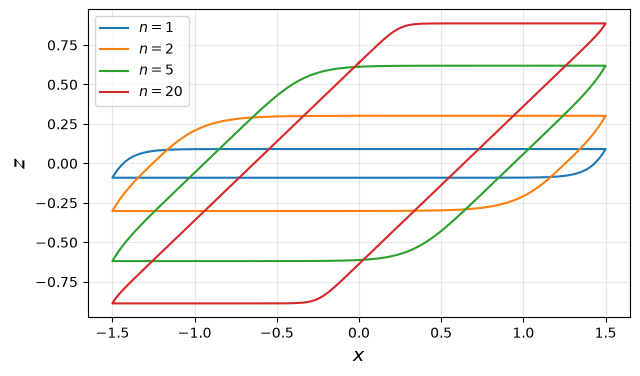

In [4]:
# Pripravljalna naloga 1: nasicena vrednost z in vpliv n na obliko z(x)
display(sp.Eq(sp.Symbol(r"\dot{z}"), zdot_sym))
display(sp.Eq(sp.Symbol("z_{nas}"), z_nas))
print("z_nas pri A=1, beta=10, gamma=1, n=2:", float(z_nas.subs({A_s: 1, b_s: 10, g_s: 1, n_s: 2})))

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for n in [1, 2, 5, 20]:
    t, x, zz = vsiljeno(n=n)
    _, x_c, z_c = zadnji_cikel(t, x, zz)
    ax.plot(x_c, z_c, label=f"$n = {n}$")
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel("$z$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

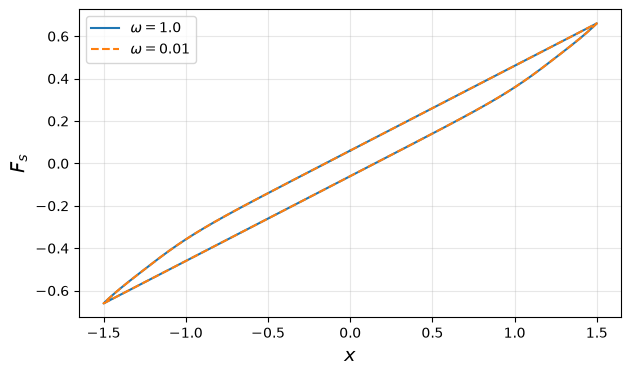

In [5]:
# Pripravljalna naloga 2: zanka je neodvisna od hitrosti obremenjevanja (kvazistaticno ostane odprta)
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for om, ls in [(1.0, "-"), (0.01, "--")]:
    t, x, zz = vsiljeno(omega=om, n_cikl=3)
    _, x_c, z_c = zadnji_cikel(t, x, zz, omega=om)
    ax.plot(x_c, F_s(x_c, z_c), ls, label=rf"$\omega = {om}$")
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel("$F_s$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Naloga 1

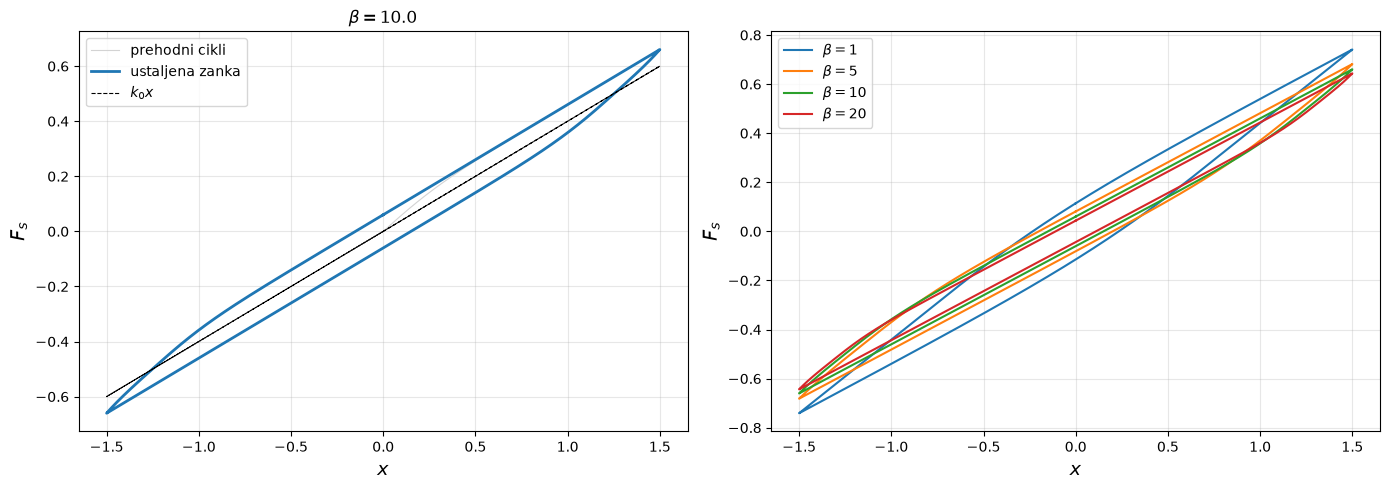

In [6]:
t, x, zz = vsiljeno()
_, x_c, z_c = zadnji_cikel(t, x, zz)

fig = plt.figure(figsize=(14, 5))
ax = fig.add_subplot(121)
ax.plot(x, F_s(x, zz), color="lightgray", linewidth=0.8, label="prehodni cikli")
ax.plot(x_c, F_s(x_c, z_c), color="C0", linewidth=2, label="ustaljena zanka")
ax.plot(x_c, k0 * x_c, "--", color="black", linewidth=0.8, label="$k_0 x$")
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel("$F_s$", fontsize=14)
ax.set_title(rf"$\beta = {beta_bw}$")
ax.legend()
ax.grid(alpha=0.3)

ax = fig.add_subplot(122)
for b in beta_list:
    t, x, zz = vsiljeno(beta=b)
    _, x_c, z_c = zadnji_cikel(t, x, zz)
    ax.plot(x_c, F_s(x_c, z_c), label=rf"$\beta = {b:.0f}$")
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel("$F_s$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Naloga 2

E(0) = 0.4500,  E(t_end) = 0.0019,  x(t_end) = +0.0266


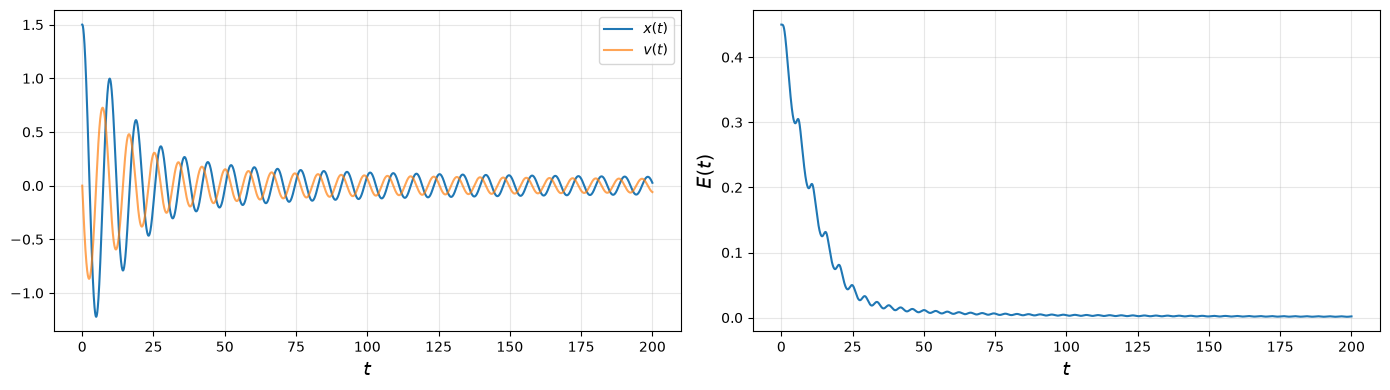

In [7]:
t_end = 200.0
t_ev = np.linspace(0, t_end, 20001)
sol = solve_ivp(rhs_prosto, (0, t_end), [1.5, 0.0, 0.0], t_eval=t_ev, rtol=rtol, atol=atol, max_step=0.05)
x_p, v_p, z_p = sol.y
E = 0.5 * m * v_p**2 + 0.5 * k0 * x_p**2
print(f"E(0) = {E[0]:.4f},  E(t_end) = {E[-1]:.4f},  x(t_end) = {x_p[-1]:+.4f}")

fig = plt.figure(figsize=(14, 4))
ax = fig.add_subplot(121)
ax.plot(sol.t, x_p, label="$x(t)$")
ax.plot(sol.t, v_p, label="$v(t)$", alpha=0.7)
ax.set_xlabel("$t$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)

ax = fig.add_subplot(122)
ax.plot(sol.t, E)
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel("$E(t)$", fontsize=14)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Naloga 3

In [8]:
# W_dis = zanka F_s dx = integral F_s v dt (en ustaljen cikel)
print(f"{'beta':>5} {'W (trapz po x)':>15} {'W (int F v dt)':>15}")
for b in beta_list:
    t, x, zz = vsiljeno(beta=b)
    t_c, x_c, z_c = zadnji_cikel(t, x, zz)
    W_x = np.trapezoid(F_s(x_c, z_c), x_c)
    W_t = np.trapezoid(F_s(x_c, z_c) * X0 * omega * np.cos(omega * t_c), t_c)
    print(f"{b:5.0f} {W_x:15.5f} {W_t:15.5f}")

 beta  W (trapz po x)  W (int F v dt)
    1         0.41141         0.41141
    5         0.36224         0.36224
   10         0.29376         0.29376
   20         0.22665         0.22665


# Razmislek 1

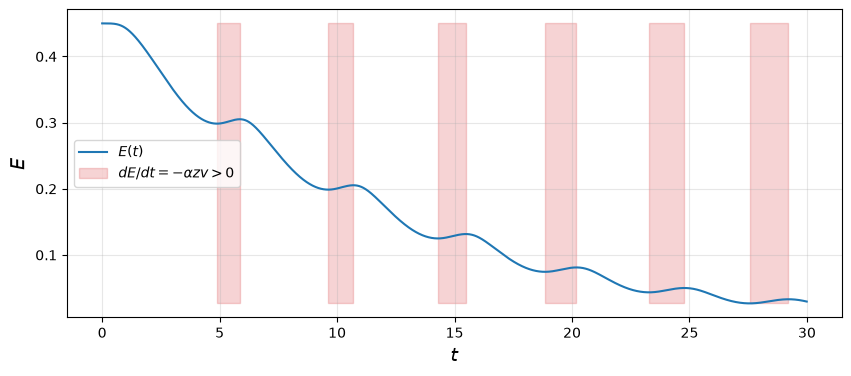

delez casa (t < 30) z dE/dt > 0: 0.26


In [9]:
# dE/dt = v (m v' + k0 x) = -alpha z v  ->  E zacasno raste, kadar je z v < 0
dEdt = -alpha * z_p * v_p
m_r = sol.t < 30

fig = plt.figure(figsize=(10, 4))
ax = fig.add_subplot(111)
ax.plot(sol.t[m_r], E[m_r], color="C0", label="$E(t)$")
ax.fill_between(sol.t[m_r], E[m_r].min(), E[m_r].max(), where=dEdt[m_r] > 0,
                color="C3", alpha=0.2, label=r"$dE/dt = -\alpha z v > 0$")
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel("$E$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print(f"delez casa (t < 30) z dE/dt > 0: {np.mean(dEdt[m_r] > 0):.2f}")